# Medellin SIC Clustering from H1 Wasserstein Diagram Distances

This notebook replicates `cluster_us_city_wasserstein.ipynb` for `processed_data/medellin_sit`.

Differences from the US-city notebook:
- no `gridiron`/`cul_de_sac` ground-truth comparison;
- only polygons with more than 10 H1 persistence-diagram points are clustered;
- both average-linkage hierarchical clustering and k-means are explored;
- cluster counts are inferred from unsupervised diagnostics, including elbow curves and silhouette scores;
- Medellin SIC polygons and OSMnx streets are mapped by cluster, with clusterless areas in gray.


In [1]:
from pathlib import Path
import json
import os
import re
import sys
import warnings

# Keep matplotlib/IPython caches inside writable locations when running from a sandboxed environment.
os.environ.setdefault('MPLCONFIGDIR', '/tmp/mplconfig')
os.environ.setdefault('IPYTHONDIR', '/tmp/ipython')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '8')

import numpy as np
import pandas as pd
import matplotlib
if 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.errors import EmptyDataError
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import squareform
from scipy.stats import skew

from sklearn.cluster import KMeans
from sklearn.manifold import MDS, TSNE
from sklearn.metrics import silhouette_score

from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')


## 1. Configure Paths


In [2]:
def find_levelset_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / 'processed_data' / 'medellin_sit').exists():
            return candidate
        nested = candidate / 'levelset_urban_ph'
        if (nested / 'processed_data' / 'medellin_sit').exists():
            return nested
    raise FileNotFoundError(f'Could not find levelset_urban_ph from {start.resolve()}')

PROJECT_ROOT = find_levelset_root()
DATA_DIR = PROJECT_ROOT / 'processed_data' / 'medellin_sit'
SHAPEFILE = PROJECT_ROOT / 'labeled_data' / 'medellin_polygons' / 'shape' / 'AMVA_EOD_2017_poligonos.shp'
OUTPUT_DIR = PROJECT_ROOT / 'notebooks_clustering' / 'clustering_medellin'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MIN_H1_POINTS = 10
RANDOM_STATE = 42
MAX_K = 12

print('Project root:', PROJECT_ROOT)
print('Processed data:', DATA_DIR)
print('Output directory:', OUTPUT_DIR)


Project root: /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban
Processed data: /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/processed_data/medellin_sit
Output directory: /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/notebooks_clustering/clustering_medellin


## 2. Load Medellin SIC H1 Diagrams


In [3]:
POLYGON_RE = re.compile(r'^polygon_(\d+)$')

def polygon_number(name: str) -> int | None:
    match = POLYGON_RE.match(name)
    return int(match.group(1)) if match else None

def polygon_sort_key(path: Path):
    number = polygon_number(path.name)
    return (number is None, number if number is not None else path.name)

def load_json(path: Path) -> dict:
    if not path.exists():
        return {}
    with path.open() as f:
        return json.load(f)

def read_h1_pairs(path: Path) -> np.ndarray:
    if not path.exists() or path.stat().st_size == 0:
        return np.empty((0, 2), dtype=float)
    try:
        df = pd.read_csv(path, header=None)
    except EmptyDataError:
        return np.empty((0, 2), dtype=float)
    arr = df.iloc[:, :2].apply(pd.to_numeric, errors='coerce').dropna().to_numpy(float)
    arr = arr[np.isfinite(arr).all(axis=1)]
    arr = arr[arr[:, 1] >= arr[:, 0]]
    return arr

def diagram_summary_features(diagram: np.ndarray) -> dict:
    if diagram.size == 0:
        return {
            'pd_count': 0, 'pd_lifetime_mean': 0, 'pd_lifetime_std': 0, 'pd_lifetime_max': 0,
            'pd_lifetime_sum': 0, 'pd_lifetime_q25': 0, 'pd_lifetime_q50': 0, 'pd_lifetime_q75': 0,
            'pd_birth_mean': 0, 'pd_death_mean': 0, 'pd_lifetime_skew': 0,
        }
    birth = diagram[:, 0]
    death = diagram[:, 1]
    lifetime = death - birth
    return {
        'pd_count': len(lifetime),
        'pd_lifetime_mean': float(np.mean(lifetime)),
        'pd_lifetime_std': float(np.std(lifetime)),
        'pd_lifetime_max': float(np.max(lifetime)),
        'pd_lifetime_sum': float(np.sum(lifetime)),
        'pd_lifetime_q25': float(np.quantile(lifetime, 0.25)),
        'pd_lifetime_q50': float(np.quantile(lifetime, 0.50)),
        'pd_lifetime_q75': float(np.quantile(lifetime, 0.75)),
        'pd_birth_mean': float(np.mean(birth)),
        'pd_death_mean': float(np.mean(death)),
        'pd_lifetime_skew': float(skew(lifetime)) if len(lifetime) > 2 else 0.0,
    }

status_records = []
included_records = []
diagrams_raw = []

for sample_dir in sorted([p for p in DATA_DIR.iterdir() if p.is_dir()], key=polygon_sort_key):
    metadata = load_json(sample_dir / 'metadata.json')
    status = load_json(sample_dir / 'status.json')
    pnum = polygon_number(sample_dir.name)
    source_row_index = metadata.get('source_row_index')
    if source_row_index is None and pnum is not None:
        source_row_index = pnum - 1

    diagram_path = sample_dir / 'h1_pairs.csv'
    diagram = read_h1_pairs(diagram_path)
    birth = diagram[:, 0] if len(diagram) else np.array([0.0])
    death = diagram[:, 1] if len(diagram) else np.array([0.0])

    record = {
        'polygon_id': sample_dir.name,
        'polygon_number': pnum,
        'source_row_index': source_row_index,
        'sit_2017': str(metadata.get('properties', {}).get('SIT_2017', '')),
        'pipeline_status': status.get('status', 'unknown'),
        'has_h1_pairs': diagram_path.exists(),
        'n_h1_pairs': len(diagram),
        'diagram_min': float(np.min(birth)),
        'diagram_max': float(np.max(death)),
        'diagram_span': float(np.max(death) - np.min(birth)),
    }

    if not diagram_path.exists():
        record['clusterless_reason'] = 'missing_outputs'
    elif len(diagram) <= MIN_H1_POINTS:
        record['clusterless_reason'] = 'too_few_h1_pairs'
    else:
        record['clusterless_reason'] = 'clustered'
        included_records.append(record)
        diagrams_raw.append(diagram)

    status_records.append(record)

sample_status = pd.DataFrame(status_records)
meta = pd.DataFrame(included_records)
diagram_features = pd.DataFrame([diagram_summary_features(d) for d in diagrams_raw])
meta_features = pd.concat([meta.reset_index(drop=True), diagram_features], axis=1)

print(f'Found {len(sample_status)} polygon folders in {DATA_DIR}')
print(f'Included {len(meta_features)} polygons with more than {MIN_H1_POINTS} H1 pairs')
display(sample_status['clusterless_reason'].value_counts(dropna=False).rename_axis('status').reset_index(name='n_polygons'))
display(meta_features[['polygon_id', 'sit_2017', 'n_h1_pairs', 'diagram_span']].head())
display(meta_features[['n_h1_pairs', 'diagram_span', 'pd_lifetime_mean', 'pd_lifetime_sum']].describe())


Found 513 polygon folders in /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/processed_data/medellin_sit
Included 340 polygons with more than 10 H1 pairs


,status,n_polygons
0,clustered,340
1,too_few_h1_pairs,167
2,missing_outputs,6


,polygon_id,sit_2017,n_h1_pairs,diagram_span
0,polygon_1,37,13,70.8
1,polygon_2,632,13,101.6
2,polygon_3,468,65,87.9
3,polygon_4,460,41,94.6
4,polygon_5,469,95,84.8


,n_h1_pairs,diagram_span,pd_lifetime_mean,pd_lifetime_sum
count,340.000000,340.000000,340.000000,340.000000
mean,38.823529,108.530294,25.736468,826.943235
std,26.754726,38.794938,14.913392,452.371031
min,11.000000,36.400000,3.797917,97.900000
25%,20.000000,77.700000,14.947560,460.300000
50%,32.000000,101.700000,22.517194,791.650000
75%,51.000000,132.250000,34.302128,1130.275000
max,177.000000,200.000000,97.775000,2703.600000


## 3. Prepare Diagrams for Wasserstein Distances


In [4]:
NORMALIZE_DIAGRAMS = True
WASSERSTEIN_ORDER = 2.0
GROUND_METRIC_ORDER = 2.0

# This normalization preserves birth/death coordinates and the diagonal y=x.
def normalize_diagram(diagram: np.ndarray) -> np.ndarray:
    diagram = np.asarray(diagram, dtype=float).reshape(-1, 2)
    if diagram.size == 0:
        return diagram
    lo = float(np.min(diagram[:, 0]))
    hi = float(np.max(diagram[:, 1]))
    span = max(hi - lo, 1e-12)
    return (diagram - lo) / span

diagrams = [normalize_diagram(d) if NORMALIZE_DIAGRAMS else np.asarray(d, dtype=float).copy() for d in diagrams_raw]

sizes = np.array([len(d) for d in diagrams])
print('Using normalized diagrams:', NORMALIZE_DIAGRAMS)
print('Wasserstein order:', WASSERSTEIN_ORDER)
print('Ground metric order:', GROUND_METRIC_ORDER)
print(f'Diagram sizes after filtering: min={sizes.min()}, max={sizes.max()}, mean={sizes.mean():.1f}')


Using normalized diagrams: True
Wasserstein order: 2.0
Ground metric order: 2.0
Diagram sizes after filtering: min=11, max=177, mean=38.8


## 4. Compute Pairwise Wasserstein Distances


In [5]:
DISTANCE_MATRIX_OUT = OUTPUT_DIR / 'cluster_medellin_sit_wasserstein_distance_matrix.csv'
RECOMPUTE_DISTANCES = False

def point_to_diagonal_distance_power(diagram: np.ndarray, p: float) -> np.ndarray:
    if diagram.size == 0:
        return np.empty(0, dtype=float)
    lifetime = np.maximum(diagram[:, 1] - diagram[:, 0], 0.0)
    # Euclidean distance from (birth, death) to the diagonal y=x is lifetime / sqrt(2).
    return (lifetime / np.sqrt(2.0)) ** p

def wasserstein_distance_pd(diagram_a: np.ndarray, diagram_b: np.ndarray, order: float = 2.0, ground_order: float = 2.0) -> float:
    a = np.asarray(diagram_a, dtype=float).reshape(-1, 2)
    b = np.asarray(diagram_b, dtype=float).reshape(-1, 2)
    n = len(a)
    m = len(b)

    if n == 0 and m == 0:
        return 0.0
    if n == 0:
        return float(np.sum(point_to_diagonal_distance_power(b, order)) ** (1.0 / order))
    if m == 0:
        return float(np.sum(point_to_diagonal_distance_power(a, order)) ** (1.0 / order))

    # Pairwise ground distances between off-diagonal points.
    diff = a[:, None, :] - b[None, :, :]
    point_cost = np.sum(np.abs(diff) ** ground_order, axis=2) ** (order / ground_order)

    cost = np.full((n + m, n + m), np.inf, dtype=float)
    cost[:n, :m] = point_cost

    # Points from each diagram can match their own diagonal copies.
    for i, c in enumerate(point_to_diagonal_distance_power(a, order)):
        cost[i, m + i] = c
    for j, c in enumerate(point_to_diagonal_distance_power(b, order)):
        cost[n + j, j] = c

    # Diagonal copies can match each other at zero cost.
    cost[n:, m:] = 0.0

    row_ind, col_ind = linear_sum_assignment(cost)
    return float(cost[row_ind, col_ind].sum() ** (1.0 / order))

def distance_matrix_matches(path: Path, samples: pd.Series) -> bool:
    if not path.exists():
        return False
    try:
        cached = pd.read_csv(path, index_col=0, nrows=1)
        return list(cached.columns) == list(samples)
    except Exception:
        return False

if distance_matrix_matches(DISTANCE_MATRIX_OUT, meta_features['polygon_id']) and not RECOMPUTE_DISTANCES:
    D_df = pd.read_csv(DISTANCE_MATRIX_OUT, index_col=0)
    D = D_df.loc[meta_features['polygon_id'], meta_features['polygon_id']].to_numpy(float)
    print(f'Loaded cached Wasserstein distance matrix from {DISTANCE_MATRIX_OUT}')
else:
    n = len(diagrams)
    D = np.zeros((n, n), dtype=float)
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]

    for k, (i, j) in enumerate(pairs, start=1):
        D[i, j] = wasserstein_distance_pd(
            diagrams[i], diagrams[j], order=WASSERSTEIN_ORDER, ground_order=GROUND_METRIC_ORDER
        )
        D[j, i] = D[i, j]
        if k % 500 == 0 or k == len(pairs):
            print(f'Computed {k:,} / {len(pairs):,} distances')

    pd.DataFrame(D, index=meta_features['polygon_id'], columns=meta_features['polygon_id']).to_csv(DISTANCE_MATRIX_OUT)
    print(f'Wrote {DISTANCE_MATRIX_OUT}')

nonzero = D[D > 0]
print('Distance matrix shape:', D.shape)
print(f'Min off-diag: {nonzero.min():.6f}, Max: {D.max():.6f}, Mean: {nonzero.mean():.6f}')


Computed 500 / 57,630 distances
Computed 1,000 / 57,630 distances
Computed 1,500 / 57,630 distances
Computed 2,000 / 57,630 distances
Computed 2,500 / 57,630 distances
Computed 3,000 / 57,630 distances
Computed 3,500 / 57,630 distances
Computed 4,000 / 57,630 distances
Computed 4,500 / 57,630 distances
Computed 5,000 / 57,630 distances
Computed 5,500 / 57,630 distances
Computed 6,000 / 57,630 distances
Computed 6,500 / 57,630 distances
Computed 7,000 / 57,630 distances
Computed 7,500 / 57,630 distances
Computed 8,000 / 57,630 distances
Computed 8,500 / 57,630 distances
Computed 9,000 / 57,630 distances
Computed 9,500 / 57,630 distances
Computed 10,000 / 57,630 distances
Computed 10,500 / 57,630 distances
Computed 11,000 / 57,630 distances
Computed 11,500 / 57,630 distances
Computed 12,000 / 57,630 distances
Computed 12,500 / 57,630 distances
Computed 13,000 / 57,630 distances
Computed 13,500 / 57,630 distances
Computed 14,000 / 57,630 distances
Computed 14,500 / 57,630 distances
Comput

## 5. Embed Wasserstein Distances for K-Means and Visualization


In [6]:
mds = MDS(
    n_components=2,
    dissimilarity='precomputed',
    random_state=RANDOM_STATE,
    normalized_stress='auto',
)
X_mds = mds.fit_transform(D)

MDS_FOR_KMEANS_COMPONENTS = 8
mds_for_kmeans = MDS(
    n_components=min(MDS_FOR_KMEANS_COMPONENTS, len(meta_features) - 1),
    dissimilarity='precomputed',
    random_state=RANDOM_STATE,
    normalized_stress='auto',
)
X_cluster = mds_for_kmeans.fit_transform(D)

print('2D MDS stress:', getattr(mds, 'stress_', np.nan))
print('K-means MDS embedding shape:', X_cluster.shape)


2D MDS stress: 2297.4402536219222
K-means MDS embedding shape: (340, 8)


## 6. Infer Cluster Counts


Hierarchical elbow k: 6; silhouette-best k: 2; selected k: 6
K-means elbow k: 5; Wasserstein-silhouette-best k: 2; selected k: 5


,k,n_clusters_observed,within_cluster_distance_ss,silhouette
0,2,2,83508.386124,0.455216
1,3,3,83287.775032,0.429538
2,4,4,83281.316354,0.426725
3,5,5,76513.305678,0.257158
4,6,6,24526.430174,0.342843
5,7,7,24510.529858,0.325719
6,8,8,20725.131917,0.335885
7,9,9,20652.261653,0.329201
8,10,10,19822.505448,0.302766
9,11,11,19814.379699,0.291534


,k,n_clusters_observed,inertia,silhouette_on_wasserstein_D,silhouette_on_mds
0,2,2,205.440536,0.403379,0.412233
1,3,3,164.704928,0.271561,0.286211
2,4,4,139.547322,0.319718,0.335036
3,5,5,119.742990,0.240813,0.260943
4,6,6,107.752358,0.259093,0.282550
5,7,7,98.955059,0.247056,0.273543
6,8,8,90.279722,0.232974,0.258816
7,9,9,83.922595,0.242748,0.269880
8,10,10,78.727028,0.194941,0.226004
9,11,11,74.591553,0.193338,0.226523


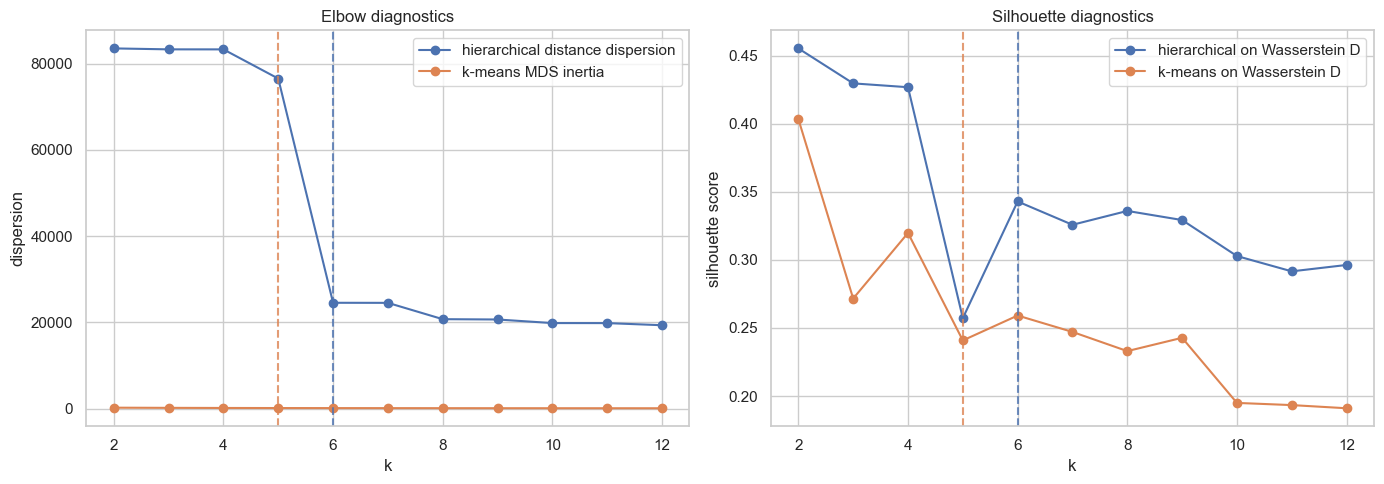

In [7]:
def candidate_k_values(n_samples: int, max_k: int = MAX_K) -> list[int]:
    return list(range(2, min(max_k, n_samples - 1) + 1))

def make_contiguous_labels(labels: np.ndarray) -> np.ndarray:
    labels = np.asarray(labels)
    mapping = {old: new for new, old in enumerate(sorted(pd.unique(labels)))}
    return np.array([mapping[x] for x in labels], dtype=int)

def safe_silhouette(data: np.ndarray, labels: np.ndarray, metric: str = 'euclidean') -> float:
    n_labels = len(np.unique(labels))
    if n_labels < 2 or n_labels >= len(labels):
        return np.nan
    return float(silhouette_score(data, labels, metric=metric))

def distance_dispersion(distance_matrix: np.ndarray, labels: np.ndarray) -> float:
    total = 0.0
    for label in np.unique(labels):
        idx = np.flatnonzero(labels == label)
        if len(idx) < 2:
            continue
        block = distance_matrix[np.ix_(idx, idx)]
        total += float(np.sum(block ** 2) / 2.0)
    return total

def elbow_k(k_values, values) -> int:
    k = np.asarray(k_values, dtype=float)
    y = np.asarray(values, dtype=float)
    valid = np.isfinite(k) & np.isfinite(y)
    k = k[valid]
    y = y[valid]
    if len(k) < 3 or np.allclose(y, y[0]):
        return int(k[0])
    x_norm = (k - k.min()) / max(k.max() - k.min(), 1e-12)
    y_norm = (y - y.min()) / max(y.max() - y.min(), 1e-12)
    points = np.column_stack([x_norm, y_norm])
    start = points[0]
    end = points[-1]
    line = end - start
    line_norm = np.linalg.norm(line)
    if line_norm == 0:
        return int(k[0])
    deltas = points - start
    distances = np.abs(line[0] * deltas[:, 1] - line[1] * deltas[:, 0]) / line_norm
    return int(k[int(np.argmax(distances))])

def best_silhouette_k(diagnostics: pd.DataFrame) -> int | None:
    valid = diagnostics.dropna(subset=['silhouette'])
    if valid.empty:
        return None
    return int(valid.loc[valid['silhouette'].idxmax(), 'k'])

candidate_ks = candidate_k_values(len(meta_features), MAX_K)
condensed_wasserstein = squareform(D, checks=False)
Z = linkage(condensed_wasserstein, method='average')

hierarchical_rows = []
for k in candidate_ks:
    labels = make_contiguous_labels(fcluster(Z, t=k, criterion='maxclust'))
    hierarchical_rows.append({
        'k': k,
        'n_clusters_observed': len(np.unique(labels)),
        'within_cluster_distance_ss': distance_dispersion(D, labels),
        'silhouette': safe_silhouette(D, labels, metric='precomputed'),
    })
hierarchical_diagnostics = pd.DataFrame(hierarchical_rows)

kmeans_rows = []
for k in candidate_ks:
    model = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE)
    labels = model.fit_predict(X_cluster)
    kmeans_rows.append({
        'k': k,
        'n_clusters_observed': len(np.unique(labels)),
        'inertia': float(model.inertia_),
        'silhouette_on_wasserstein_D': safe_silhouette(D, labels, metric='precomputed'),
        'silhouette_on_mds': safe_silhouette(X_cluster, labels, metric='euclidean'),
    })
kmeans_diagnostics = pd.DataFrame(kmeans_rows)

hierarchical_elbow_k = elbow_k(hierarchical_diagnostics['k'], hierarchical_diagnostics['within_cluster_distance_ss'])
hierarchical_silhouette_k = best_silhouette_k(hierarchical_diagnostics)
kmeans_elbow_k = elbow_k(kmeans_diagnostics['k'], kmeans_diagnostics['inertia'])
kmeans_silhouette_k = int(kmeans_diagnostics.loc[kmeans_diagnostics['silhouette_on_wasserstein_D'].idxmax(), 'k'])

# Optional manual overrides after inspecting the diagnostics. Leave as None for inferred cluster counts.
OVERRIDE_HIERARCHICAL_K = None
OVERRIDE_KMEANS_K = None
SELECTED_HIERARCHICAL_K = OVERRIDE_HIERARCHICAL_K or hierarchical_elbow_k
SELECTED_KMEANS_K = OVERRIDE_KMEANS_K or kmeans_elbow_k

print(f'Hierarchical elbow k: {hierarchical_elbow_k}; silhouette-best k: {hierarchical_silhouette_k}; selected k: {SELECTED_HIERARCHICAL_K}')
print(f'K-means elbow k: {kmeans_elbow_k}; Wasserstein-silhouette-best k: {kmeans_silhouette_k}; selected k: {SELECTED_KMEANS_K}')
display(hierarchical_diagnostics)
display(kmeans_diagnostics)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(hierarchical_diagnostics['k'], hierarchical_diagnostics['within_cluster_distance_ss'], marker='o', label='hierarchical distance dispersion')
axes[0].plot(kmeans_diagnostics['k'], kmeans_diagnostics['inertia'], marker='o', label='k-means MDS inertia')
axes[0].axvline(SELECTED_HIERARCHICAL_K, color='C0', linestyle='--', alpha=0.8)
axes[0].axvline(SELECTED_KMEANS_K, color='C1', linestyle='--', alpha=0.8)
axes[0].set_title('Elbow diagnostics')
axes[0].set_xlabel('k')
axes[0].set_ylabel('dispersion')
axes[0].legend()

axes[1].plot(hierarchical_diagnostics['k'], hierarchical_diagnostics['silhouette'], marker='o', label='hierarchical on Wasserstein D')
axes[1].plot(kmeans_diagnostics['k'], kmeans_diagnostics['silhouette_on_wasserstein_D'], marker='o', label='k-means on Wasserstein D')
axes[1].axvline(SELECTED_HIERARCHICAL_K, color='C0', linestyle='--', alpha=0.8)
axes[1].axvline(SELECTED_KMEANS_K, color='C1', linestyle='--', alpha=0.8)
axes[1].set_title('Silhouette diagnostics')
axes[1].set_xlabel('k')
axes[1].set_ylabel('silhouette score')
axes[1].legend()

plt.tight_layout()
plt.show()


## 7. Fit Hierarchical and K-Means Clusters


In [8]:
hierarchical_labels = make_contiguous_labels(fcluster(Z, t=SELECTED_HIERARCHICAL_K, criterion='maxclust'))
kmeans_model = KMeans(n_clusters=SELECTED_KMEANS_K, n_init=100, random_state=RANDOM_STATE)
kmeans_labels = kmeans_model.fit_predict(X_cluster)

meta_features['hierarchical_cluster'] = hierarchical_labels
meta_features['kmeans_cluster'] = kmeans_labels

print('Hierarchical cluster sizes')
display(meta_features['hierarchical_cluster'].value_counts().sort_index().rename_axis('cluster').reset_index(name='n_polygons'))
print('K-means cluster sizes')
display(meta_features['kmeans_cluster'].value_counts().sort_index().rename_axis('cluster').reset_index(name='n_polygons'))
print('Cross-tabulation of the two unsupervised clusterings')
display(pd.crosstab(meta_features['hierarchical_cluster'], meta_features['kmeans_cluster']))


Hierarchical cluster sizes


,cluster,n_polygons
0,0,8
1,1,222
2,2,89
3,3,18
4,4,2
5,5,1


K-means cluster sizes


,cluster,n_polygons
0,0,44
1,1,102
2,2,46
3,3,112
4,4,36


Cross-tabulation of the two unsupervised clusterings


kmeans_cluster,0,1,2,3,4
hierarchical_cluster,,,,,
0,7,0,0,0,1
1,12,97,1,112,0
2,25,5,45,0,14
3,0,0,0,0,18
4,0,0,0,0,2
5,0,0,0,0,1


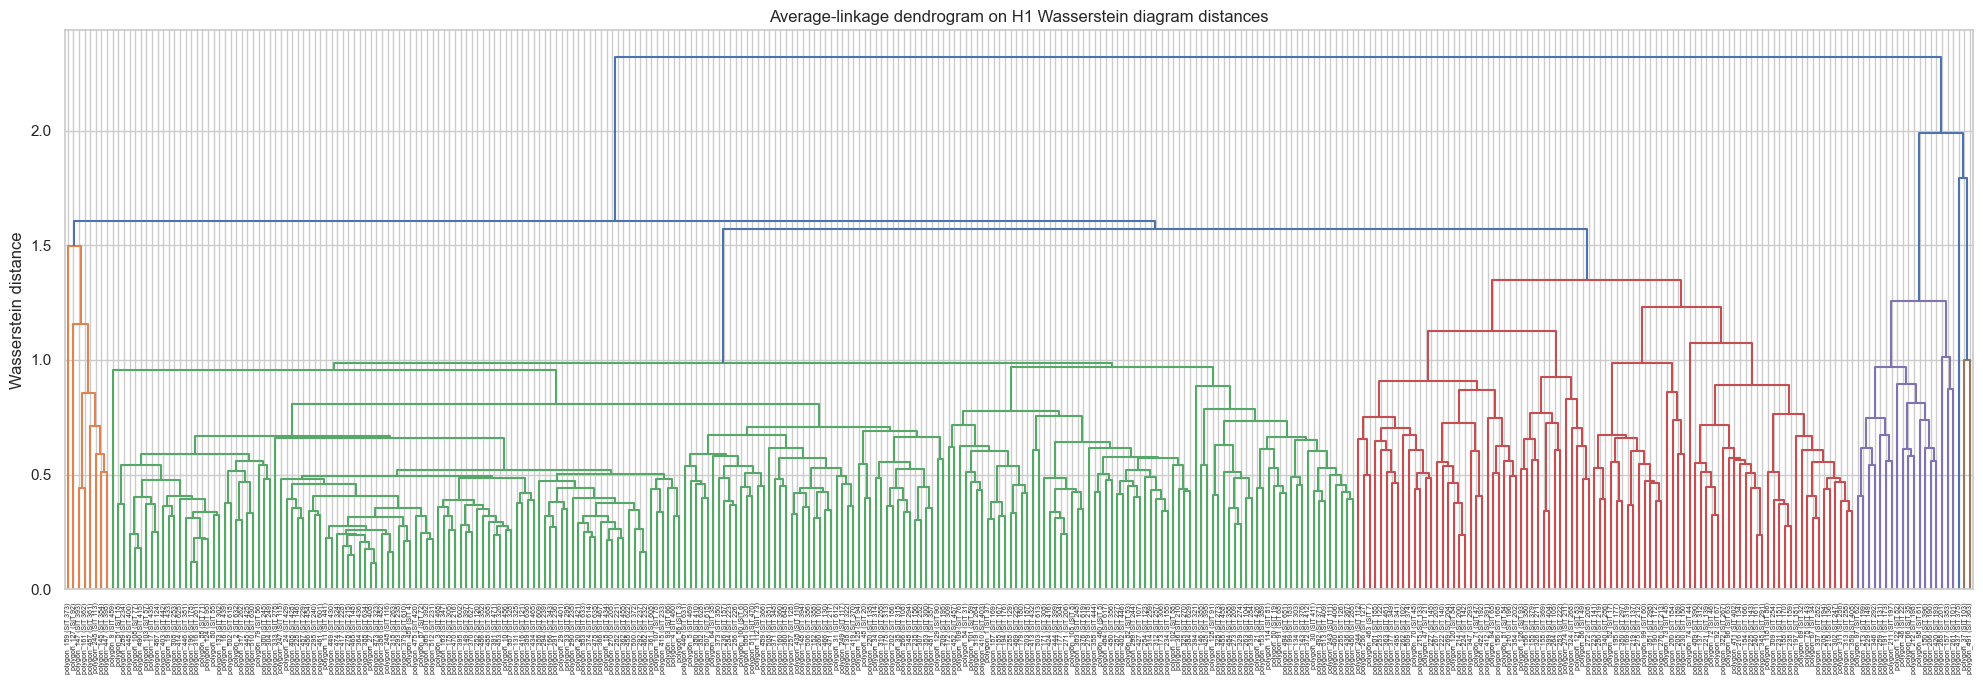

In [9]:
plt.figure(figsize=(20, 7))
leaf_labels = [f"{row.polygon_id} (SIT {row.sit_2017})" for row in meta_features.itertuples()]
dendrogram(
    Z,
    labels=leaf_labels,
    leaf_rotation=90,
    leaf_font_size=5,
    color_threshold=Z[-SELECTED_HIERARCHICAL_K + 1, 2] if SELECTED_HIERARCHICAL_K > 1 else None,
)
plt.title('Average-linkage dendrogram on H1 Wasserstein diagram distances')
plt.ylabel('Wasserstein distance')
plt.tight_layout()
plt.show()


## 8. MDS and t-SNE Visualizations


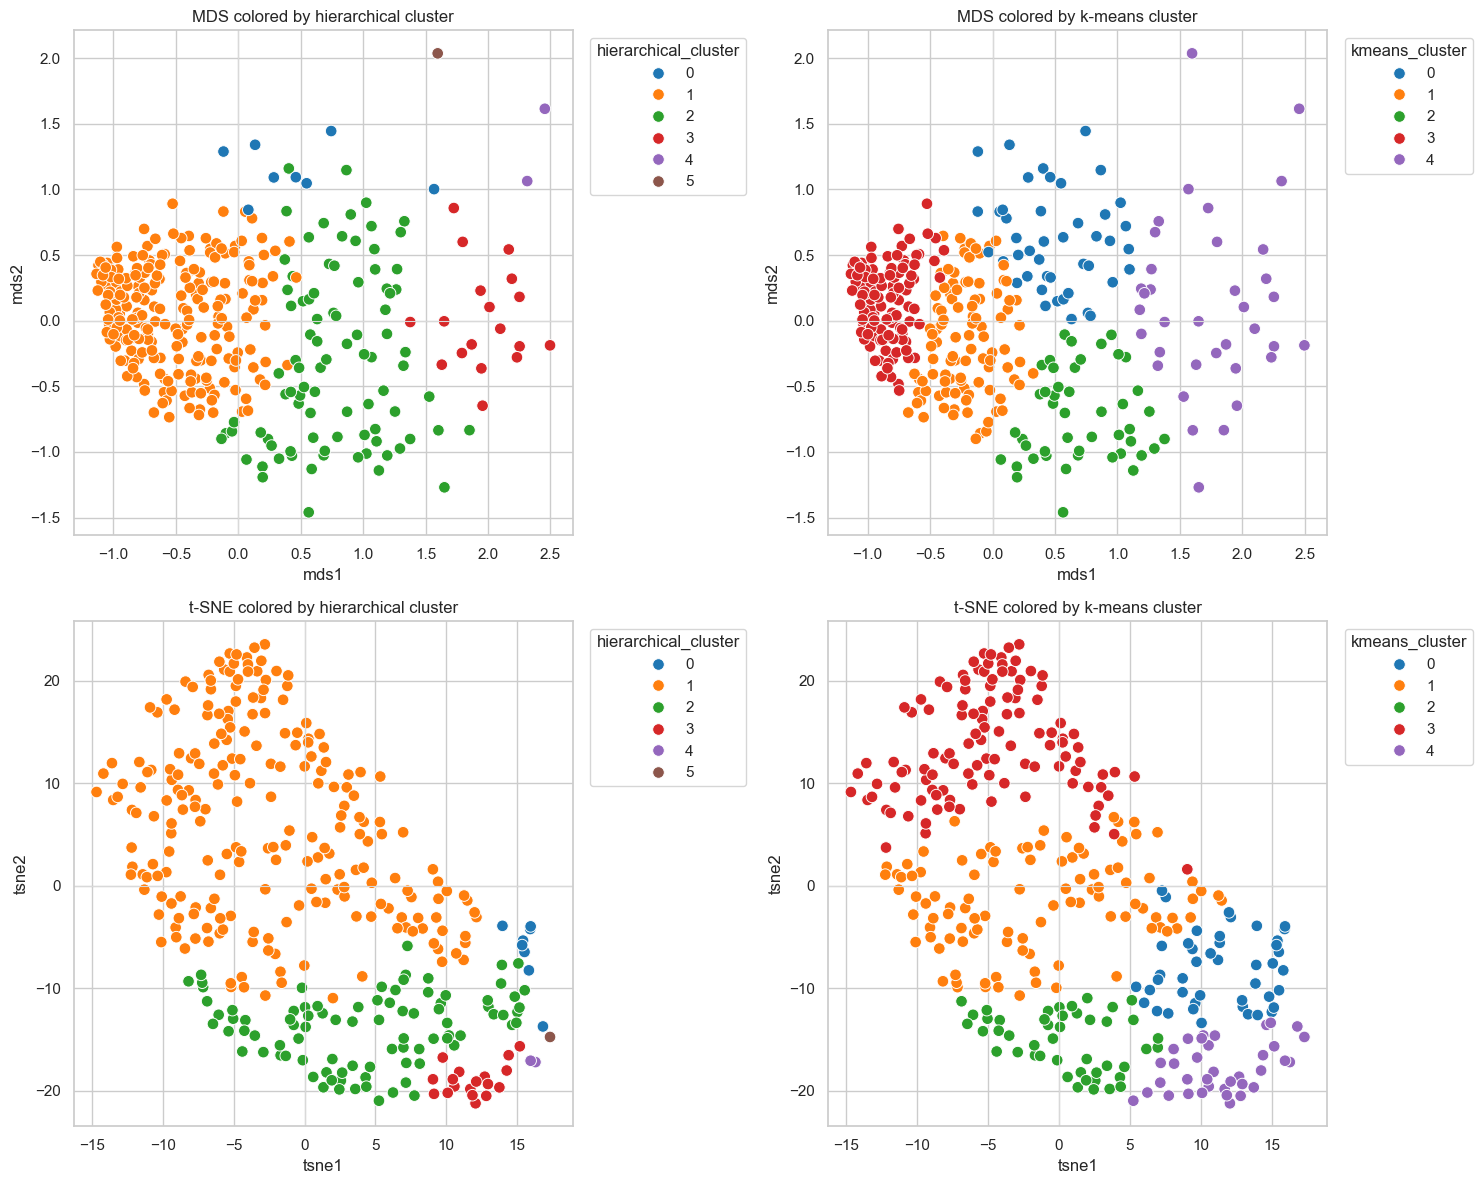

In [10]:
tsne = TSNE(
    n_components=2,
    metric='precomputed',
    perplexity=min(30, max(5, (len(meta_features) - 1) // 3)),
    init='random',
    learning_rate='auto',
    random_state=RANDOM_STATE,
)
X_tsne = tsne.fit_transform(D)

viz = meta_features.copy()
viz['mds1'] = X_mds[:, 0]
viz['mds2'] = X_mds[:, 1]
viz['tsne1'] = X_tsne[:, 0]
viz['tsne2'] = X_tsne[:, 1]

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
plot_specs = [
    ('hierarchical_cluster', 'MDS colored by hierarchical cluster', 'mds1', 'mds2'),
    ('kmeans_cluster', 'MDS colored by k-means cluster', 'mds1', 'mds2'),
    ('hierarchical_cluster', 't-SNE colored by hierarchical cluster', 'tsne1', 'tsne2'),
    ('kmeans_cluster', 't-SNE colored by k-means cluster', 'tsne1', 'tsne2'),
]
for ax, (cluster_col, title, x_col, y_col) in zip(axes.ravel(), plot_specs):
    sns.scatterplot(data=viz, x=x_col, y=y_col, hue=cluster_col, palette='tab10', s=70, ax=ax)
    ax.set_title(title)
    ax.axhline(0, color='0.85', linewidth=0.8)
    ax.axvline(0, color='0.85', linewidth=0.8)
    ax.legend(title=cluster_col, bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()


## 9. Cluster Summaries


hierarchical_cluster


n_h1_pairs                         diagram_span           \
                          count     mean median     std        count     mean   
hierarchical_cluster                                                            
0                             8  107.875  108.0  23.443            8   82.275   
1                           222   37.090   28.5  27.264          222  123.857   
2                            89   33.798   32.0  15.321           89   83.747   
3                            18   45.722   42.5  12.778           18   65.050   
4                             2   77.000   77.0   2.828            2   37.750   
5                             1  118.000  118.0     NaN            1   46.000   

                                     pd_count           ... pd_lifetime_sum  \
                      median     std    count     mean  ...          median   
hierarchical_cluster                                    ...                   
0                      77.05  14.073        8  107.875  ...         1804.80   
1                     121.05  37.456      222   37.090  ...          559.55   
2                      81.50  20.162       89   33.798  ...         1090.60   
3                      66.25  12.629       18   45.722  ...         1506.20   
4                      37.75   1.626        2   77.000  ...         1419.75   
5                      46.00     NaN        1  118.000  ...         2046.20   

                              pd_lifetime_q50                          \
                          std           count    mean  median     std   
hierarchical_cluster                                                    
0                     430.801               8  17.500  16.700   4.351   
1                     321.023             222  14.550  10.500  12.630   
2                     299.882              89  40.466  37.500  20.479   
3                     239.111              18  37.089  41.025  12.738   
4                     168.645               2  21.500  21.500   3.960   
5                         NaN               1  18.400  18.400     NaN   

                     pd_lifetime_q75                          
                               count    mean  median     std  
hierarchical_cluster                                          
0                                  8  22.616  24.325   4.103  
1                                222  27.448  21.788  18.458  
2                                 89  53.029  52.300  21.594  
3                                 18  47.815  50.288  10.158  
4                                  2  25.550  25.550   1.414  
5                                  1  21.300  21.300     NaN  

[6 rows x 36 columns]

kmeans_cluster


n_h1_pairs                        diagram_span           \
                    count    mean median     std        count     mean   
kmeans_cluster                                                           
0                      44  58.273   52.0  22.985           44   88.580   
1                     102  38.873   30.0  26.329          102  103.771   
2                      46  25.130   22.0  10.099           46   89.061   
3                     112  33.000   24.0  28.259          112  141.944   
4                      36  50.528   42.5  25.465           36   67.325   

                               pd_count          ... pd_lifetime_sum           \
                median     std    count    mean  ...          median      std   
kmeans_cluster                                   ...                            
0                88.45  23.275       44  58.273  ...         1281.45  332.450   
1               102.00  30.224      102  38.873  ...          730.25  249.229   
2                88.75  20.201       46  25.130  ...          998.85  199.101   
3               139.90  36.006      112  33.000  ...          386.80  223.634   
4                67.35  15.998       36  50.528  ...         1440.25  337.215   

               pd_lifetime_q50                         pd_lifetime_q75  \
                         count    mean  median     std           count   
kmeans_cluster                                                           
0                           44  25.243  23.150   9.548              44   
1                          102  19.024  13.975  15.154             102   
2                           46  48.959  48.200  22.242              46   
3                          112   9.750   7.700   7.834             112   
4                           36  36.257  38.250  14.042              36   

                                        
                  mean  median     std  
kmeans_cluster                          
0               32.638  29.662  10.448  
1               34.890  30.712  20.719  
2               65.174  60.950  20.872  
3               20.554  18.487  13.768  
4               45.338  47.988  13.412  

[5 rows x 36 columns]

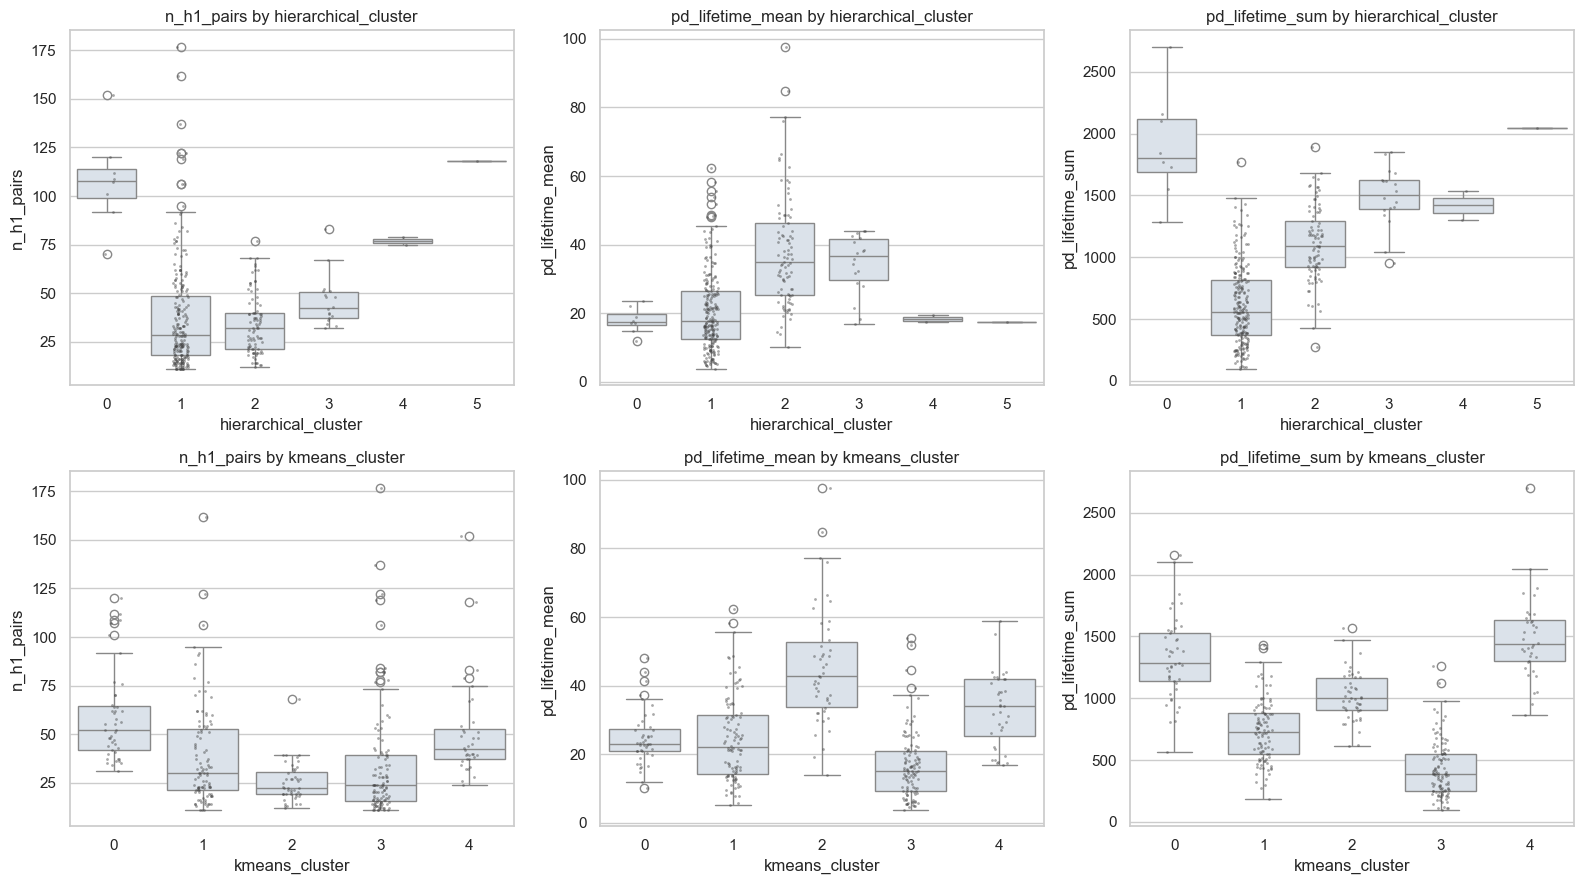

In [11]:
summary_cols = [
    'n_h1_pairs', 'diagram_span', 'pd_count', 'pd_lifetime_mean', 'pd_lifetime_std',
    'pd_lifetime_max', 'pd_lifetime_sum', 'pd_lifetime_q50', 'pd_lifetime_q75'
]

for cluster_col in ['hierarchical_cluster', 'kmeans_cluster']:
    print(cluster_col)
    cluster_summary = meta_features.groupby(cluster_col)[summary_cols].agg(['count', 'mean', 'median', 'std']).round(3)
    display(cluster_summary)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for row, cluster_col in enumerate(['hierarchical_cluster', 'kmeans_cluster']):
    for ax, metric in zip(axes[row], ['n_h1_pairs', 'pd_lifetime_mean', 'pd_lifetime_sum']):
        sns.boxplot(data=meta_features, x=cluster_col, y=metric, ax=ax, color='#d9e2ec')
        sns.stripplot(data=meta_features, x=cluster_col, y=metric, ax=ax, color='0.25', size=2, alpha=0.45)
        ax.set_title(f'{metric} by {cluster_col}')
plt.tight_layout()
plt.show()


## 10. Medellin Polygon Maps


Map assignment status


,status,n_polygons
0,clustered,340
1,too_few_h1_pairs,167
2,missing_outputs,6


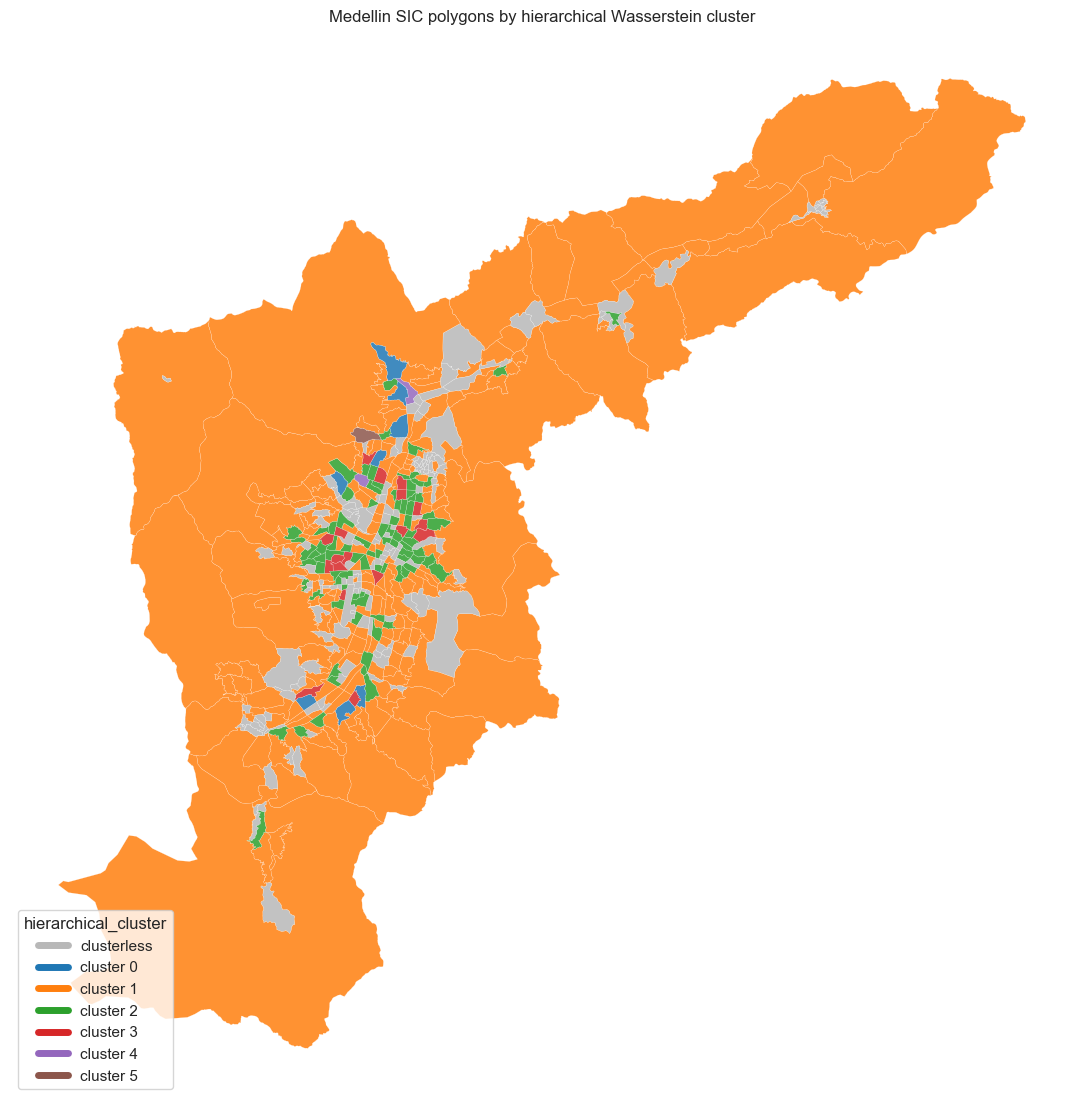

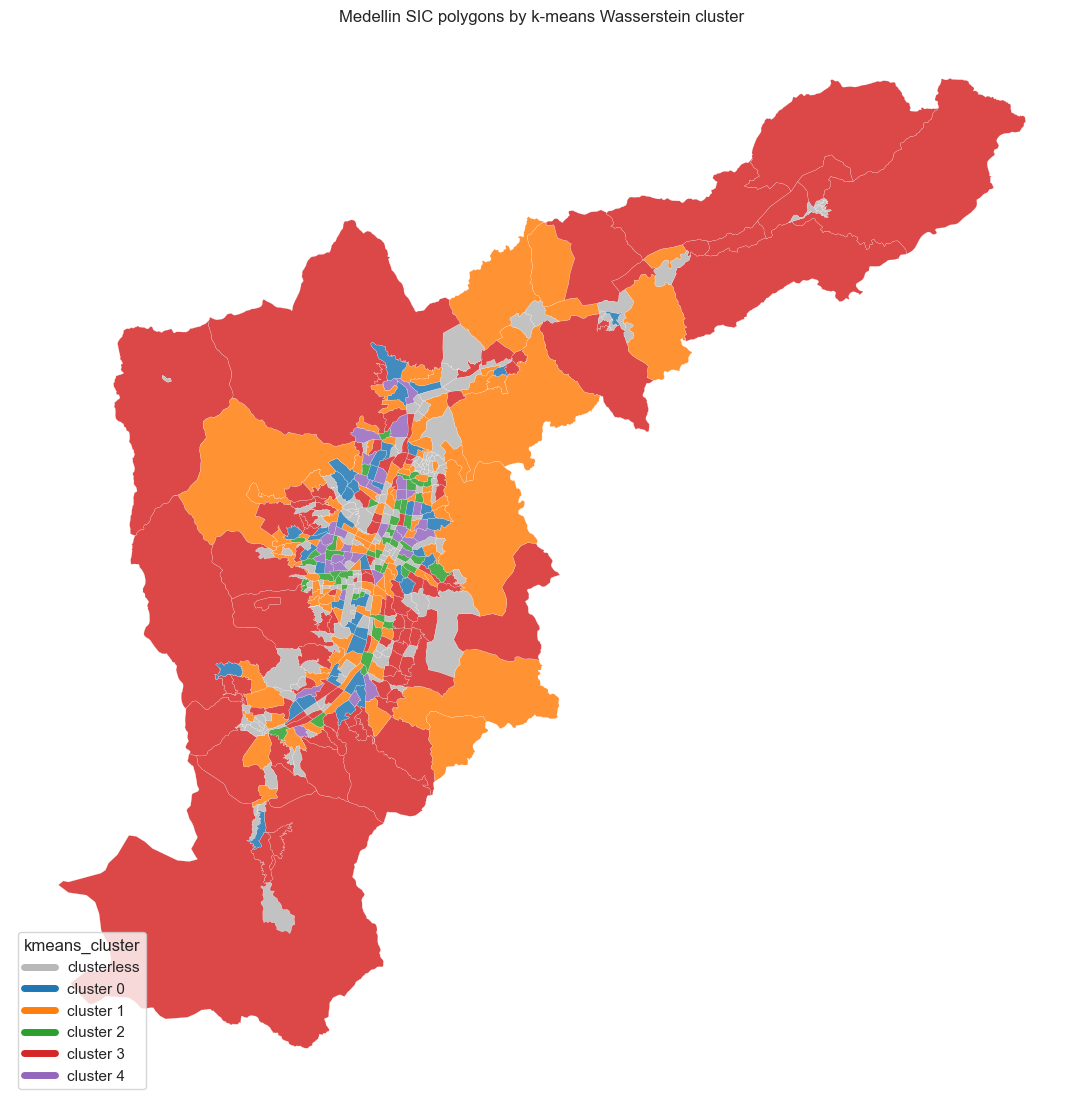

In [12]:
import geopandas as gpd
import osmnx as ox
from matplotlib.lines import Line2D

CLUSTERLESS_COLOR = '#b8b8b8'
CLUSTER_COLORS = (
    sns.color_palette('tab10', 10).as_hex()
    + sns.color_palette('Set2', 8).as_hex()
    + sns.color_palette('Dark2', 8).as_hex()
)

def cluster_color_map(labels) -> dict:
    unique = sorted(pd.Series(labels).dropna().astype(int).unique())
    return {label: CLUSTER_COLORS[i % len(CLUSTER_COLORS)] for i, label in enumerate(unique)}

def load_medellin_polygons() -> gpd.GeoDataFrame:
    gdf = gpd.read_file(SHAPEFILE).to_crs('EPSG:4326')
    gdf = gdf.reset_index().rename(columns={'index': 'source_row_index'})
    gdf['polygon_id'] = 'polygon_' + (gdf['source_row_index'] + 1).astype(str)
    gdf['sit_2017'] = gdf['SIT_2017'].astype(str)

    cluster_cols = [
        'source_row_index', 'n_h1_pairs', 'clusterless_reason',
        'hierarchical_cluster', 'kmeans_cluster'
    ]
    assignments = sample_status.merge(
        meta_features[['source_row_index', 'hierarchical_cluster', 'kmeans_cluster']],
        on='source_row_index', how='left'
    )
    return gdf.merge(assignments[cluster_cols], on='source_row_index', how='left')

def plot_polygon_cluster_map(polygons: gpd.GeoDataFrame, cluster_col: str, title: str):
    colors = cluster_color_map(polygons[cluster_col])
    plot_gdf = polygons.copy()
    plot_gdf['plot_color'] = plot_gdf[cluster_col].map(colors).fillna(CLUSTERLESS_COLOR)

    fig, ax = plt.subplots(figsize=(11, 13))
    plot_gdf.plot(ax=ax, color=plot_gdf['plot_color'], edgecolor='white', linewidth=0.15, alpha=0.85)
    ax.set_title(title)
    ax.set_axis_off()

    handles = [Line2D([0], [0], color=CLUSTERLESS_COLOR, lw=5, label='clusterless')]
    handles += [Line2D([0], [0], color=color, lw=5, label=f'cluster {label}') for label, color in colors.items()]
    ax.legend(handles=handles, loc='lower left', frameon=True, title=cluster_col)
    plt.tight_layout()
    plt.show()

medellin_polygons = load_medellin_polygons()
print('Map assignment status')
display(medellin_polygons['clusterless_reason'].fillna('missing_processed_output').value_counts().rename_axis('status').reset_index(name='n_polygons'))

plot_polygon_cluster_map(medellin_polygons, 'hierarchical_cluster', 'Medellin SIC polygons by hierarchical Wasserstein cluster')
plot_polygon_cluster_map(medellin_polygons, 'kmeans_cluster', 'Medellin SIC polygons by k-means Wasserstein cluster')


## 11. OSMnx Street Maps


Loading cached OSMnx edges from: /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/notebooks_clustering/clustering_medellin/medellin_sit_osmnx_drive_edges.geojson
OSMnx street edges: 72,496
PDF saved to: /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/notebooks_clustering/clustering_medellin/medellin_osmnx_hierarchical_clusters.pdf


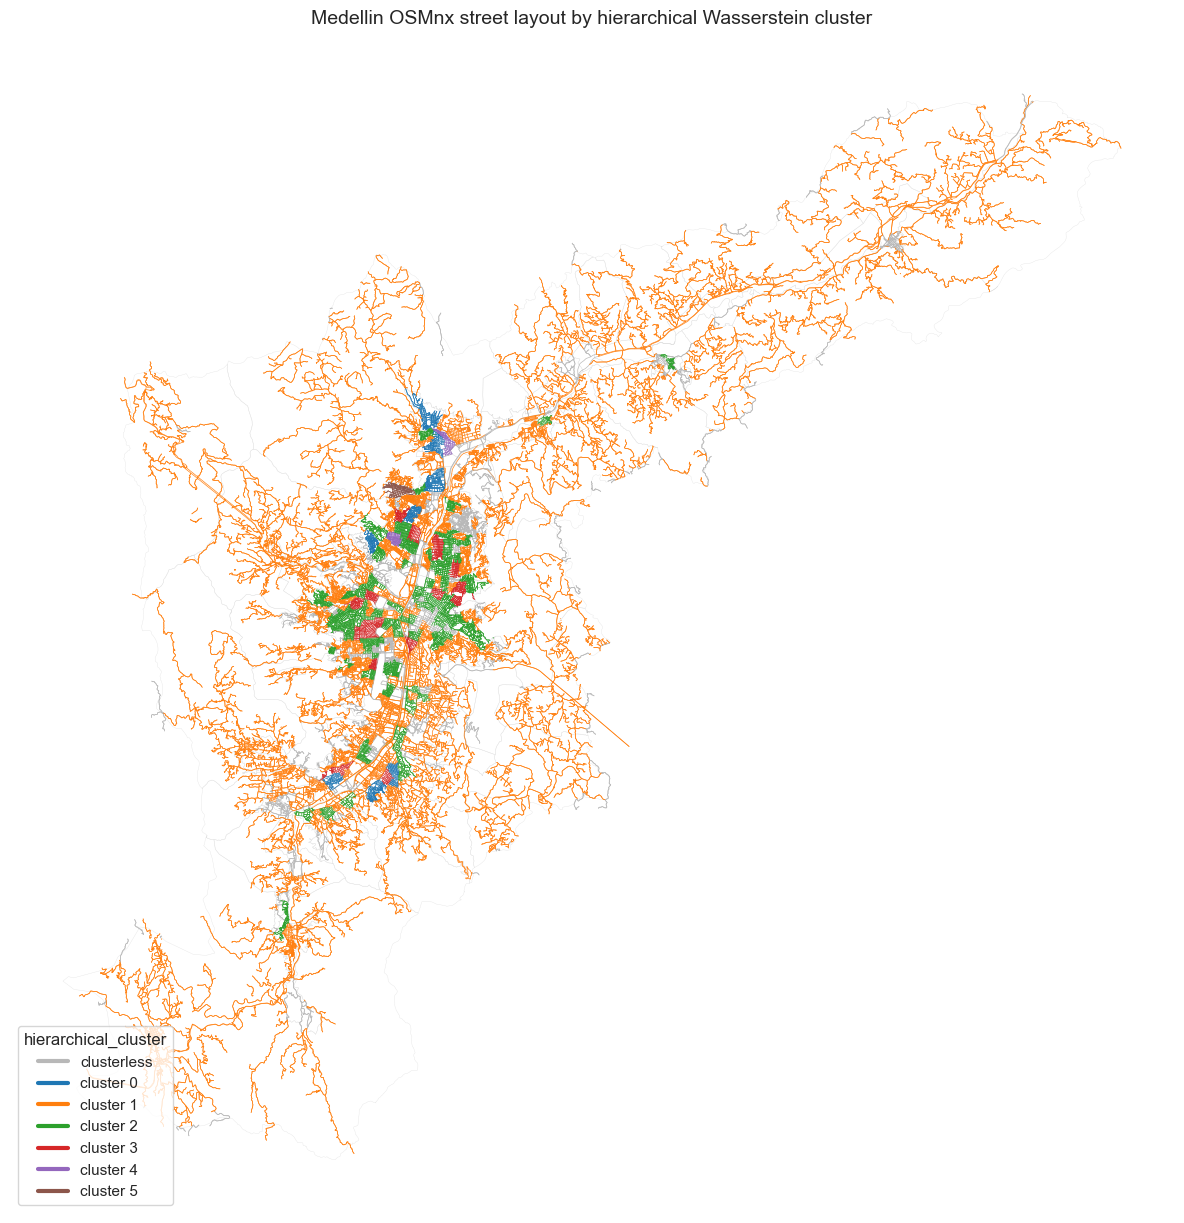

PDF saved to: /Users/gregorioperez/Documents/Maestria/Investigacion/levelset_urban/notebooks_clustering/clustering_medellin/medellin_osmnx_kmeans_clusters.pdf


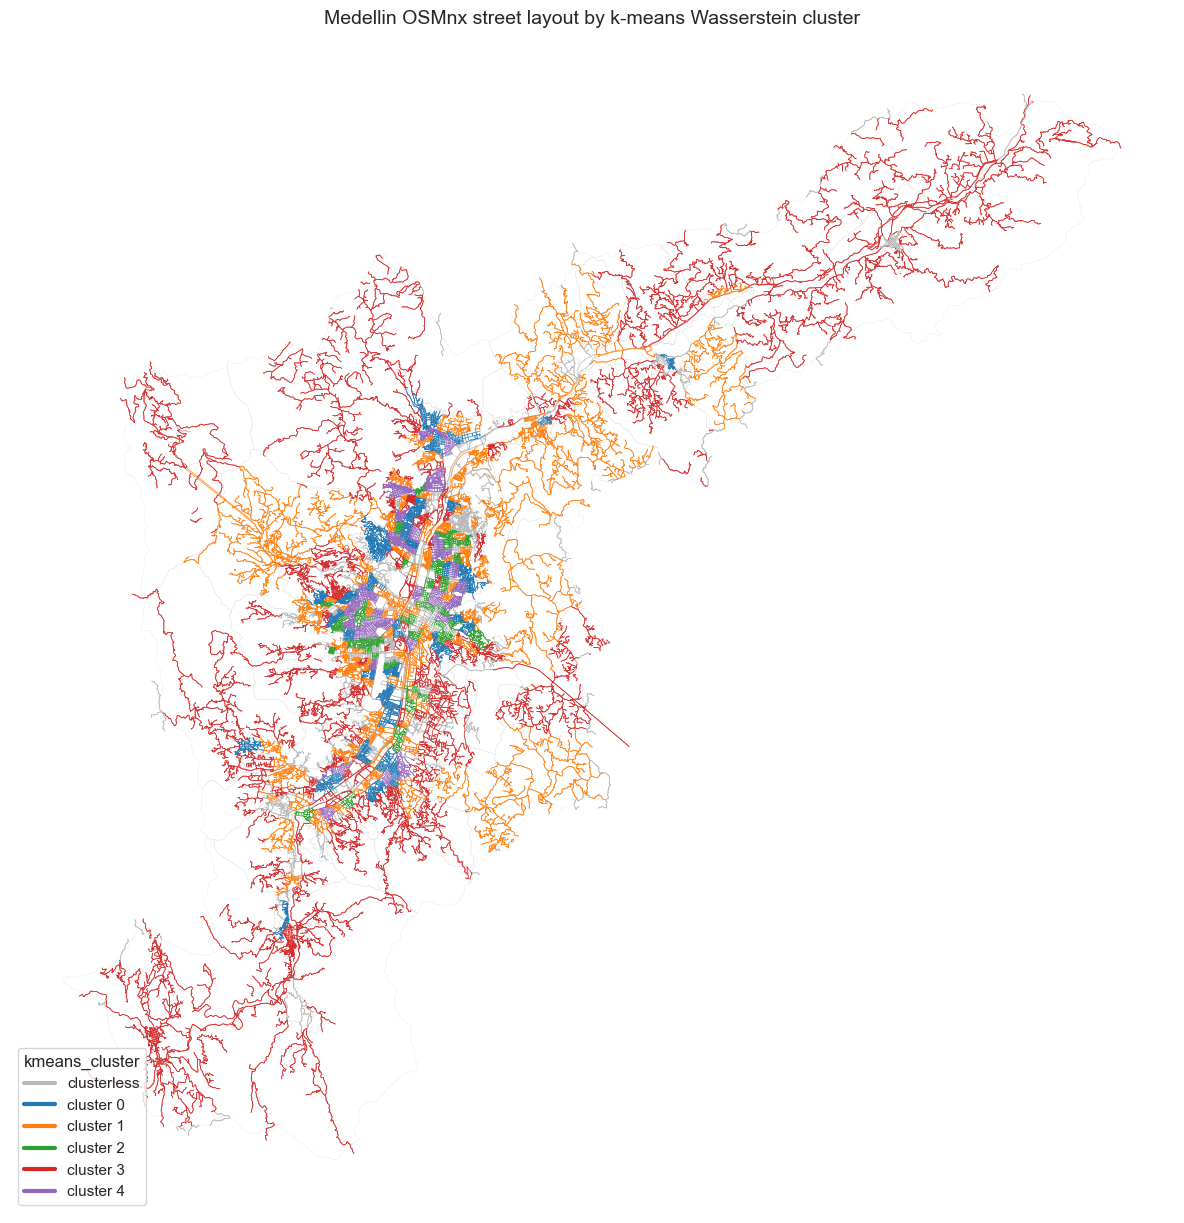

In [15]:
from pathlib import Path
from matplotlib.lines import Line2D

RUN_OSMNX_DOWNLOAD = True
OSMNX_NETWORK_TYPE = "drive"

OSMNX_EDGES_CACHE = (
    OUTPUT_DIR / "medellin_sit_osmnx_drive_edges.geojson"
)

ox.settings.use_cache = True
ox.settings.cache_folder = str(OUTPUT_DIR / "osmnx_cache")
ox.settings.log_console = False


def polygon_union(polygons: gpd.GeoDataFrame):
    """Return a single geometry containing all polygon geometries."""
    if hasattr(polygons.geometry, "union_all"):
        return polygons.geometry.union_all()

    return polygons.geometry.unary_union


def load_or_download_osmnx_edges(
    polygons: gpd.GeoDataFrame,
) -> gpd.GeoDataFrame:
    """Load cached OSMnx street edges or download them if needed."""

    if OSMNX_EDGES_CACHE.exists():
        print(f"Loading cached OSMnx edges from: {OSMNX_EDGES_CACHE}")

        return (
            gpd.read_file(OSMNX_EDGES_CACHE)
            .to_crs(polygons.crs)
        )

    if not RUN_OSMNX_DOWNLOAD:
        raise RuntimeError(
            f"{OSMNX_EDGES_CACHE} does not exist. "
            "Set RUN_OSMNX_DOWNLOAD=True to fetch it with OSMnx."
        )

    boundary = polygon_union(polygons)

    G = ox.graph_from_polygon(
        boundary,
        network_type=OSMNX_NETWORK_TYPE,
        simplify=True,
        retain_all=True,
        truncate_by_edge=True,
    )

    edges = ox.graph_to_gdfs(
        G,
        nodes=False,
        edges=True,
        fill_edge_geometry=True,
    ).to_crs(polygons.crs)

    edges = (
        edges.reset_index(drop=True)
        [["geometry"]]
        .copy()
    )

    OSMNX_EDGES_CACHE.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    edges.to_file(
        OSMNX_EDGES_CACHE,
        driver="GeoJSON",
    )

    print(f"OSMnx edges saved to: {OSMNX_EDGES_CACHE}")

    return edges


def attach_edge_clusters(
    edges: gpd.GeoDataFrame,
    polygons: gpd.GeoDataFrame,
    cluster_col: str,
) -> gpd.GeoDataFrame:
    """Assign each street edge the cluster of the polygon containing it."""

    edges_work = edges.reset_index(drop=True).copy()
    edges_work["edge_id"] = np.arange(len(edges_work))

    edge_points = edges_work[
        ["edge_id", "geometry"]
    ].copy()

    edge_points["geometry"] = (
        edge_points.geometry.representative_point()
    )

    join_cols = [
        "source_row_index",
        cluster_col,
        "geometry",
    ]

    joined = gpd.sjoin(
        edge_points,
        polygons[join_cols],
        how="left",
        predicate="within",
    )

    labels = (
        joined
        .drop_duplicates("edge_id")
        .set_index("edge_id")[cluster_col]
    )

    edges_work[cluster_col] = (
        edges_work["edge_id"].map(labels)
    )

    return edges_work


def plot_osmnx_street_cluster_map(
    edges: gpd.GeoDataFrame,
    polygons: gpd.GeoDataFrame,
    cluster_col: str,
    title: str,
    output_pdf: Path | str | None = None,
):
    """Plot an OSMnx street cluster map and optionally save it as PDF."""

    street_clusters = attach_edge_clusters(
        edges=edges,
        polygons=polygons,
        cluster_col=cluster_col,
    )

    colors = cluster_color_map(
        polygons[cluster_col]
    )

    street_clusters["plot_color"] = (
        street_clusters[cluster_col]
        .map(colors)
        .fillna(CLUSTERLESS_COLOR)
    )

    fig, ax = plt.subplots(
        figsize=(12, 14)
    )

    polygons.boundary.plot(
        ax=ax,
        color="0.86",
        linewidth=0.25,
        alpha=0.8,
    )

    street_clusters.plot(
        ax=ax,
        color=street_clusters["plot_color"],
        linewidth=0.5,
        alpha=0.95,
    )

    ax.set_title(
        title,
        fontsize=14,
        pad=12,
    )

    ax.set_axis_off()

    handles = [
        Line2D(
            [0],
            [0],
            color=CLUSTERLESS_COLOR,
            linewidth=3,
            label="clusterless",
        )
    ]

    handles += [
        Line2D(
            [0],
            [0],
            color=color,
            linewidth=3,
            label=f"cluster {label}",
        )
        for label, color in colors.items()
    ]

    ax.legend(
        handles=handles,
        loc="lower left",
        frameon=True,
        title=cluster_col,
    )

    fig.tight_layout()

    if output_pdf is not None:
        output_pdf = Path(output_pdf)

        output_pdf.parent.mkdir(
            parents=True,
            exist_ok=True,
        )

        fig.savefig(
            output_pdf,
            format="pdf",
            bbox_inches="tight",
        )

        print(f"PDF saved to: {output_pdf}")

    plt.show()
    plt.close(fig)


try:
    street_edges = load_or_download_osmnx_edges(
        medellin_polygons
    )

    print(
        f"OSMnx street edges: "
        f"{len(street_edges):,}"
    )

    plot_osmnx_street_cluster_map(
        edges=street_edges,
        polygons=medellin_polygons,
        cluster_col="hierarchical_cluster",
        title=(
            "Medellin OSMnx street layout by "
            "hierarchical Wasserstein cluster"
        ),
        output_pdf=(
            OUTPUT_DIR
            / "medellin_osmnx_hierarchical_clusters.pdf"
        ),
    )

    plot_osmnx_street_cluster_map(
        edges=street_edges,
        polygons=medellin_polygons,
        cluster_col="kmeans_cluster",
        title=(
            "Medellin OSMnx street layout by "
            "k-means Wasserstein cluster"
        ),
        output_pdf=(
            OUTPUT_DIR
            / "medellin_osmnx_kmeans_clusters.pdf"
        ),
    )

except Exception as exc:
    print(
        "OSMnx street map could not be built in this run."
    )

    print(
        type(exc).__name__ + ":",
        exc,
    )

    print(
        "If this is an internet or Overpass issue, "
        "rerun this cell later. The polygon maps above "
        "do not need OSMnx."
    )

## 12. Save Assignments


In [ ]:
ASSIGNMENTS_OUT = OUTPUT_DIR / 'cluster_medellin_sit_wasserstein_assignments.csv'
ALL_POLYGONS_OUT = OUTPUT_DIR / 'cluster_medellin_sit_wasserstein_all_polygons.csv'

output_cols = [
    'polygon_id', 'polygon_number', 'source_row_index', 'sit_2017', 'n_h1_pairs',
    'hierarchical_cluster', 'kmeans_cluster',
    'diagram_span', 'pd_lifetime_mean', 'pd_lifetime_max', 'pd_lifetime_sum',
    'mds1', 'mds2', 'tsne1', 'tsne2'
]

all_assignments = sample_status.merge(
    viz[['source_row_index', 'hierarchical_cluster', 'kmeans_cluster', 'mds1', 'mds2', 'tsne1', 'tsne2']],
    on='source_row_index', how='left', suffixes=('', '_clustered')
)

viz[output_cols].to_csv(ASSIGNMENTS_OUT, index=False)
all_assignments.to_csv(ALL_POLYGONS_OUT, index=False)

print(f'Wrote {ASSIGNMENTS_OUT}')
print(f'Wrote {ALL_POLYGONS_OUT}')
print(f'Distance matrix is at {DISTANCE_MATRIX_OUT}')
display(viz[output_cols].head())


## Notes

Cluster IDs are arbitrary and have no ground-truth urban-form interpretation here. Hierarchical clustering is performed directly on Wasserstein distances. K-means is performed on an MDS embedding because k-means requires coordinate features rather than a precomputed distance matrix.

Polygons with 10 or fewer H1 diagram points, missing outputs, or failed outputs are excluded from clustering and appear as clusterless in the maps.
